# 02 · Data selection, transformation and descriptive visualisation

Input: `reviews_clean.parquet` from notebook 01 (one row per cleaned review, cars and hotels).

1. **Data selection**: keep the task-relevant attributes (by cardinality and redundancy) and
   the task-relevant rows (by the long tail).
2. **Data transformation**: normalisation, discretisation / concept hierarchies, and the
   encodings each mining task needs.
3. **Visualisation**: the ten course plots (pie, doughnut, histogram, dot plot, stem-and-leaf,
   scatter, box plot, Pareto, radar, area), plus four supporting charts (heatmap, bar, line,
   100 % stacked bar). Every figure is followed by its inferences.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import plots as P          # shared style + plot helpers (src/plots.py)

warnings.filterwarnings("ignore", category=FutureWarning)
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
TABLES = Path("../outputs/tables")
pd.set_option("display.width", 180)

df = pd.read_parquet(CLEAN / "reviews_clean.parquet")
H, C = df[df["domain"] == "hotel"], df[df["domain"] == "car"]
print(f"{len(df):,} clean reviews: {len(H):,} hotel, {len(C):,} car")
CITY_COLORS = P.entity_palette(H["city_name"].value_counts())       # top-7 cities keep one colour everywhere
MAKE_COLORS = P.entity_palette(C["make"].value_counts())

261,330 clean reviews: 220,485 hotel, 40,845 car


## 1 · Data selection
### 1a · Attribute relevance by cardinality
An attribute whose values are (almost) all distinct, such as a free-text field, a file name or an
author, behaves like an ID. It cannot generalise, so it is not used as a descriptive or mining
attribute. (AUTHOR was already dropped in notebook 01: it is nearly unique per review and is
personal data.)

In [2]:
attrs = ["domain", "city_name", "entity", "make", "model", "model_year", "date", "title", "text",
         "favorite", "file", "encoding", "word_count", "char_count", "sentence_count", "avg_word_len",
         "title_words", "exclaim_count", "upper_ratio", "n_aspects", "sentiment", "sent_class"]
decision = {
    "domain": "keep: separates the two sub-datasets", "city_name": "keep: hotel grouping (10 values)",
    "entity": "keep: grouping for per-hotel / per-model statistics", "make": "keep: car grouping",
    "model": "keep (with make)", "model_year": "keep: car grouping (3 values)",
    "date": "keep: time attribute (concept hierarchy)", "title": "drop for mining: ID-like free text",
    "text": "source of aspects, sentiment and TF-IDF; not used directly as a category",
    "favorite": "drop: car-only free text", "file": "drop: technical ID", "encoding": "drop: technical",
}
card = pd.DataFrame({"dtype": df[attrs].dtypes.astype(str), "distinct values": df[attrs].nunique(),
                     "distinct / rows %": (df[attrs].nunique() / len(df) * 100).round(2),
                     "missing %": (df[attrs].isna().mean() * 100).round(2)})
card["decision"] = [decision.get(a, "numeric: candidate (see redundancy check)") for a in attrs]
card

,dtype,distinct values,distinct / rows %,missing %,decision
domain,str,2,0.00,0.00,keep: separates the two sub-datasets
city_name,str,10,0.00,15.63,keep: hotel grouping (10 values)
entity,str,2706,1.04,0.00,keep: grouping for per-hotel / per-model stati...
make,str,30,0.01,84.37,keep: car grouping
model,str,281,0.11,84.37,keep (with make)
model_year,float64,3,0.00,84.37,keep: car grouping (3 values)
date,datetime64[us],2484,0.95,0.59,keep: time attribute (concept hierarchy)
title,str,161357,61.74,0.00,drop for mining: ID-like free text
text,str,261330,100.00,0.00,"source of aspects, sentiment and TF-IDF; not u..."
favorite,str,38488,14.73,0.00,drop: car-only free text


**Inferences**
* `text` (100 % distinct) and `title` (~62 % distinct) behave like identifiers. They are the
  *source* of features, not usable categories. `file` and `encoding` are technical.
* The grouping attributes have low cardinality: 10 cities, 30 makes, 281 car models,
  3 model years. These are good axes for comparison plots.
* The missing values in `city_name` (≈16 %) and `make`/`model` (≈84 %) are **structural**: a car
  has no city and a hotel has no make. They are not dirty data.

### 1b · Redundancy check: correlation analysis (supporting plot: heatmap)
Redundant (derivable) attributes are detected with correlation analysis. A pair with
|r| ≥ 0.9 carries the same information twice, so one attribute of the pair is dropped.

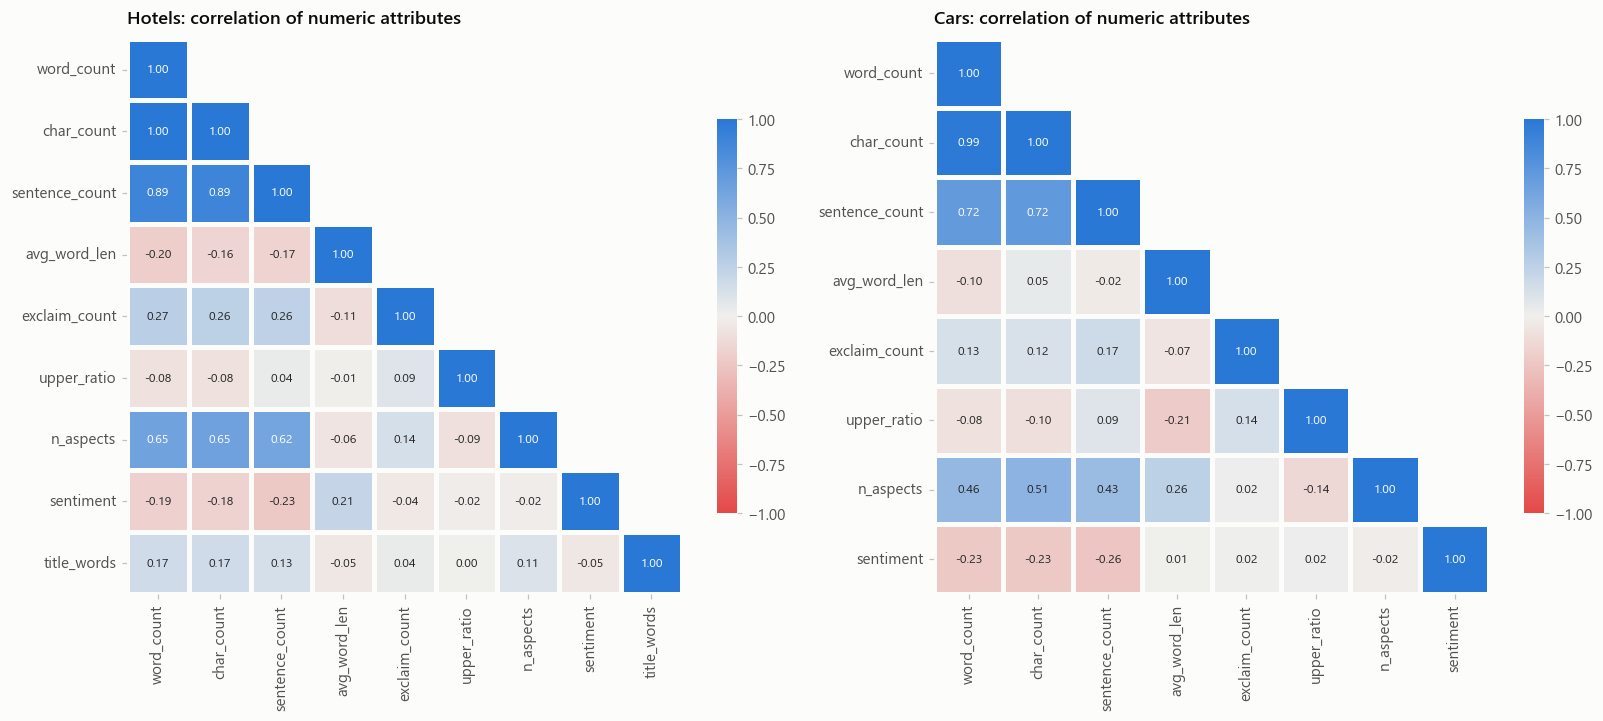

hotel pairs with |r| >= 0.5: [('word_count', 'char_count', np.float64(0.998)), ('word_count', 'sentence_count', np.float64(0.894)), ('char_count', 'sentence_count', np.float64(0.894)), ('char_count', 'n_aspects', np.float64(0.654)), ('word_count', 'n_aspects', np.float64(0.645)), ('sentence_count', 'n_aspects', np.float64(0.619))]
car pairs with |r| >= 0.5: [('word_count', 'char_count', np.float64(0.986)), ('char_count', 'sentence_count', np.float64(0.722)), ('word_count', 'sentence_count', np.float64(0.718)), ('char_count', 'n_aspects', np.float64(0.505))]


In [3]:
num = ["word_count", "char_count", "sentence_count", "avg_word_len", "exclaim_count", "upper_ratio",
       "n_aspects", "sentiment"]
corr_h = H[num + ["title_words"]].corr()
corr_c = C[num].corr()
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2))
P.corr_heatmap(axs[0], corr_h, "Hotels: correlation of numeric attributes")
P.corr_heatmap(axs[1], corr_c, "Cars: correlation of numeric attributes")
fig.tight_layout()
P.save(fig, "s11_heatmap_correlation")
plt.show()
for name, cm in [("hotel", corr_h), ("car", corr_c)]:
    pairs = [(a, b, round(cm.loc[a, b], 3)) for i, a in enumerate(cm.columns) for b in cm.columns[i + 1:]
             if abs(cm.loc[a, b]) >= 0.5]
    print(name, "pairs with |r| >= 0.5:", sorted(pairs, key=lambda x: -abs(x[2])))

**Inferences (correlation heatmap)**
* `word_count` and `char_count` are almost perfectly correlated (r ≈ 1.00 for hotels, 0.99 for
  cars). One is derivable from the other, so **`char_count` is dropped** (redundancy).
* `sentence_count` follows length closely (r ≈ 0.89 for hotels) but stays below the 0.9 cut-off,
  so it is kept. `n_aspects` rises with length (r ≈ 0.65): longer reviews cover more aspects.
* **Sentiment is not correlated with any style attribute** (|r| < 0.5): how long or how
  emphatic a review is says little about its polarity. Sentiment has to come from the words.

### 1c · Row selection: the long tail of hotels (Pareto chart, panel b)
Many hotels have only a handful of reviews. Per-hotel statistics (mean sentiment, aspect profile)
from fewer than 10 reviews are unreliable, so those hotels are left out of the per-entity
analyses. The Pareto chart shows how few hotels hold most of the reviews.

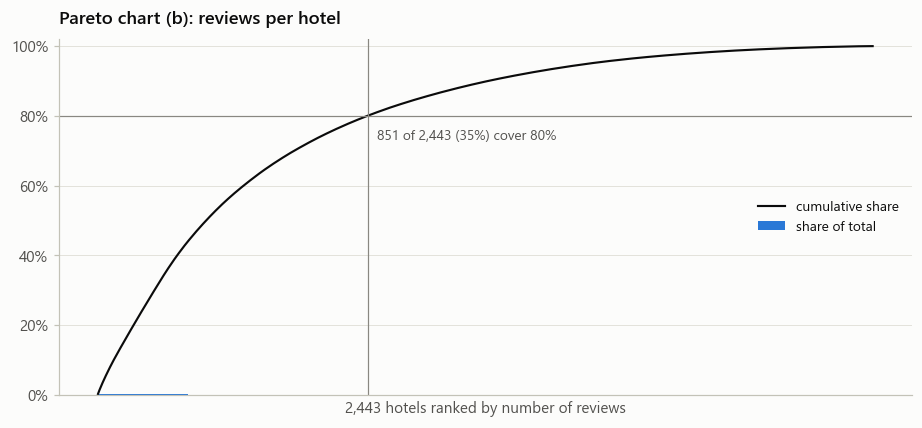

hotels: 2,443; 851 hotels (34.8%) hold 80% of the reviews
hotels with < 10 reviews: 374 (15.3% of hotels) holding 2,187 reviews (0.99% of hotel reviews)
reviews per hotel: {'count': 2443.0, 'mean': 90.3, 'std': 107.8, 'min': 1.0, '25%': 16.0, '50%': 44.0, '75%': 117.5, 'max': 576.0}


In [4]:
per_hotel = H.groupby(["city_name", "entity"]).size()
fig, ax = plt.subplots(figsize=(10, 4.2))
k80 = P.pareto(ax, per_hotel, "Pareto chart (b): reviews per hotel", P.DOMAIN["hotel"],
               xlabel=f"{len(per_hotel):,} hotels ranked by number of reviews")
P.save(fig, "p08b_pareto_reviews_per_hotel")
plt.show()
small = per_hotel[per_hotel < 10]
print(f"hotels: {len(per_hotel):,}; {k80} hotels ({k80 / len(per_hotel):.1%}) hold 80% of the reviews")
print(f"hotels with < 10 reviews: {len(small):,} ({len(small) / len(per_hotel):.1%} of hotels) "
      f"holding {small.sum():,} reviews ({small.sum() / len(H):.2%} of hotel reviews)")
print("reviews per hotel:", per_hotel.describe().round(1).to_dict())

**Inferences (Pareto chart b)**
* Reviews are concentrated: about **35 % of the hotels hold 80 % of all hotel reviews**. The
  median hotel has 44 reviews, the largest 576.
* About 15 % of hotels have fewer than 10 reviews, yet together they hold **under 1 %** of the
  reviews. Dropping them from per-hotel analyses loses almost no data and removes the noisiest
  per-hotel averages.

### 1d · Vocabulary selection: which aspects matter (Pareto chart, panel a)
Each review's aspects come from a 22-aspect hotel lexicon and a 19-aspect car lexicon. The Pareto
chart ranks the aspects by the share of all mentions and finds the "vital few" covering 80 %.
These shares also guide the minimum support used for Apriori in notebook 03.

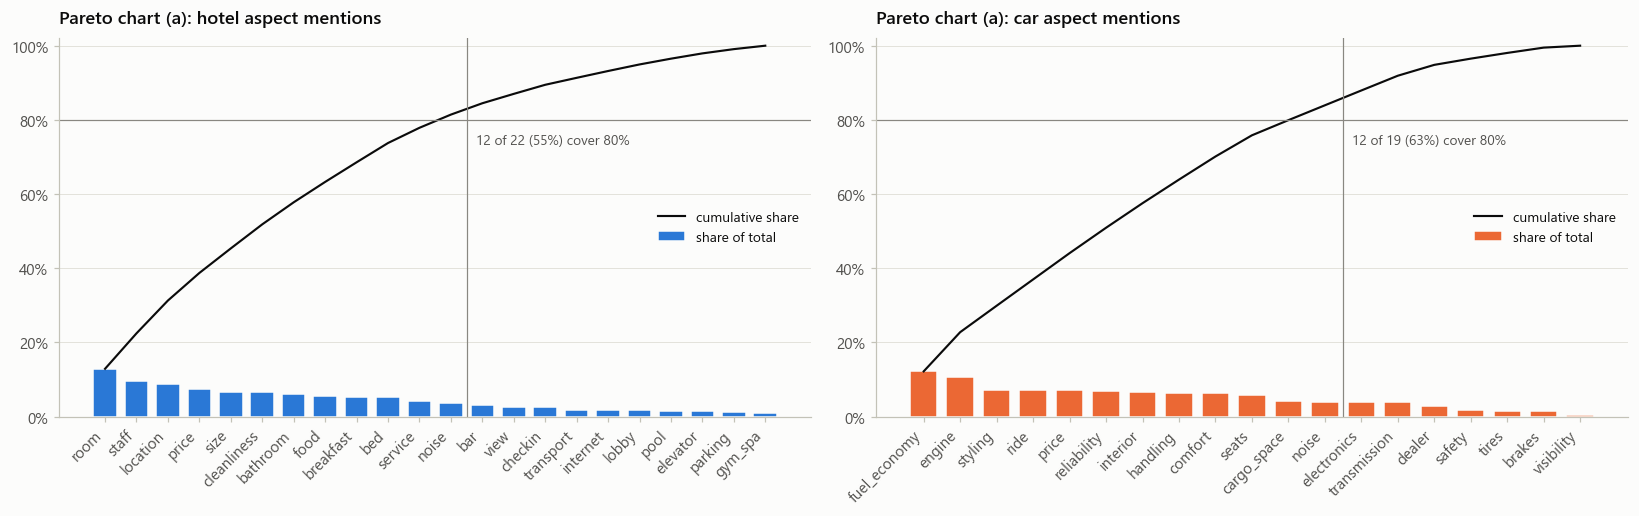

hotel: 12 of 22 aspects cover 80% of mentions; car: 12 of 19
        aspects  hotel % reviews       aspects  car % reviews
0          room             88.3  fuel_economy           46.1
1         staff             65.6        engine           40.0
2      location             60.7       styling           27.0
3         price             51.0          ride           26.9
4          size             45.4         price           26.8
5   cleanliness             44.5   reliability           25.9
6      bathroom             40.8      interior           25.1
7          food             37.7      handling           24.1
8     breakfast             36.3       comfort           23.6
9           bed             35.7         seats           21.6
10      service             28.2   cargo_space           15.5
11        noise             24.4         noise           15.2


In [5]:
asp_h = H["aspects"].explode().value_counts()
asp_c = C["aspects"].explode().value_counts()
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
k_h = P.pareto(axs[0], asp_h, "Pareto chart (a): hotel aspect mentions", P.DOMAIN["hotel"])
k_c = P.pareto(axs[1], asp_c, "Pareto chart (a): car aspect mentions", P.DOMAIN["car"])
fig.tight_layout()
P.save(fig, "p08a_pareto_aspects")
plt.show()
cov = pd.DataFrame({"hotel: % of reviews": (asp_h / len(H) * 100).round(1)}).head(12)
print(f"hotel: {k_h} of {len(asp_h)} aspects cover 80% of mentions; car: {k_c} of {len(asp_c)}")
print(pd.concat([(asp_h / len(H) * 100).round(1).rename("hotel % reviews").reset_index(),
                 (asp_c / len(C) * 100).round(1).rename("car % reviews").reset_index()], axis=1).head(12).to_string())

**Inferences (Pareto chart a)**
* Hotel reviews revolve around a few aspects. *room* appears in ~88 % of reviews, *staff* in
  ~66 % and *location* in ~61 %, and 12 of the 22 aspects cover 80 % of all mentions.
* Car reviews are less concentrated. The leaders are *fuel economy* (~46 %) and *engine*
  (~40 %), then a flat plateau (styling, ride, price, reliability, interior at 24–27 %).
  Again 12 of 19 aspects reach 80 %.
* Because the top aspects are so frequent, Apriori's minimum support must be fairly high
  (5 % for hotels) to avoid an explosion of itemsets. Cars, with lower aspect frequencies, need
  a lower one (2 %).

## 2 · Data transformation (part 2)
### 2a · Normalisation
* min-max: v' = (v − min) / (max − min), maps to [0, 1]
* z-score: v' = (v − μ) / σ
* decimal scaling: v' = v / 10^j, where j is the smallest integer with max |v'| < 1

All three are applied to `word_count` per domain, because the two domains have different
length scales. Sentiment is already on [−1, 1].

In [6]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())


def zscore(s):
    return (s - s.mean()) / s.std()


def decimal_scale(s):
    j = int(np.ceil(np.log10(s.abs().max() + 1)))
    return s / 10 ** j, j


df["wc_minmax"] = df.groupby("domain")["word_count"].transform(minmax).round(4)
df["wc_z"] = df.groupby("domain")["word_count"].transform(zscore).round(3)
ds, j = decimal_scale(df.loc[df["domain"] == "hotel", "word_count"])
print(f"decimal scaling (hotels): max |v| = {df.loc[df['domain'] == 'hotel', 'word_count'].max()}, j = {j}")
print(df.loc[df["domain"] == "hotel", ["word_count", "wc_minmax", "wc_z"]].sample(6, random_state=1)
      .assign(wc_decimal=lambda d: d["word_count"] / 10 ** j).to_string())

decimal scaling (hotels): max |v| = 3885, j = 4
        word_count  wc_minmax   wc_z  wc_decimal
120797         139     0.0345 -0.311      0.0139
200257         211     0.0531  0.173      0.0211
79642           30     0.0064 -1.044      0.0030
57379           67     0.0160 -0.795      0.0067
103536          82     0.0198 -0.694      0.0082
152155         140     0.0348 -0.304      0.0140


### 2b · Discretisation and concept hierarchies
* sentiment (continuous) → `sent_class` ∈ {neg, neu, pos}, with VADER's ±0.05 cut-offs
* length → `len_class` ∈ {short, medium, long}: **equal-depth** (`qcut`) tertiles per domain
* date → day < month < quarter < year (concept-hierarchy climbing)
* cars: make > model > model year; hotels: city > hotel

In [7]:
df["len_class"] = df.groupby("domain")["word_count"].transform(
    lambda s: pd.qcut(s, 3, labels=["short", "medium", "long"])).astype(str)
print(df.groupby(["domain", "len_class"])["word_count"].agg(["min", "max", "size"]))
print("\nconcept hierarchy on date, roll-up to year and quarter (hotel reviews):")
print(df[df["domain"] == "hotel"].groupby(["year", "quarter"]).size().unstack(fill_value=0))

                  min   max   size
domain len_class                  
car    long       114   187  13515
       medium      71   113  13530
       short        5    70  13800
hotel  long       198  3885  73379
       medium     110   197  72696
       short        5   109  74410

concept hierarchy on date, roll-up to year and quarter (hotel reviews):


quarter      1      2      3      4
year                               
2001         0      0      0      1
2002        11      9     17     33
2003        47    142    418    840
2004      1539   2263   3230   3453
2005      3917   4794   5310   4905
2006      5270   6230   6776   6843
2007      7529   8802  10930  10288
2008     11062  12159  13798  12210
2009     13772  20081  25215  17038


## 3 · The ten course plots
### Plot 1 · Pie chart: hotel reviews by city

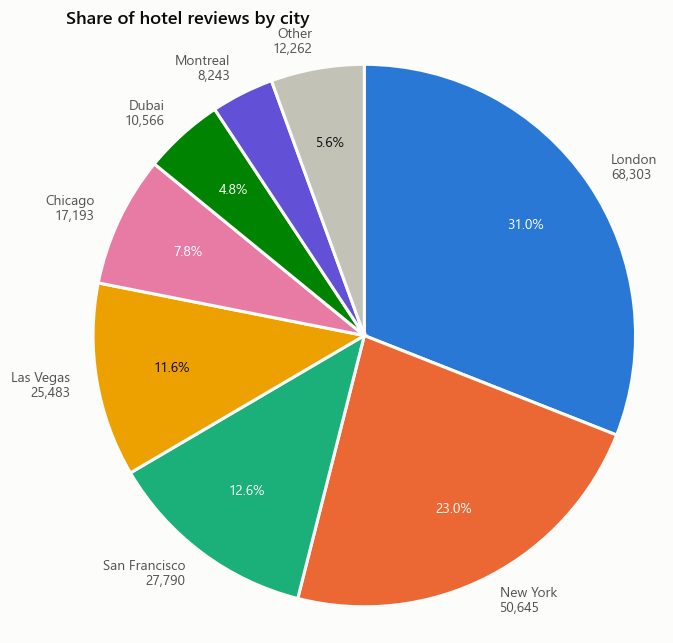

city_name
London           31.0
New York         23.0
San Francisco    12.6
Las Vegas        11.6
Chicago           7.8
Dubai             4.8
Montreal          3.7
Beijing           2.0
New Delhi         2.0
Shanghai          1.5


In [8]:
city_counts = H["city_name"].value_counts()
fig, ax = plt.subplots(figsize=(7, 7))
P.pie(ax, city_counts, "Share of hotel reviews by city", palette=CITY_COLORS)
P.save(fig, "p01_pie_city")
plt.show()
print((city_counts / city_counts.sum() * 100).round(1).to_string())

**Inferences (pie chart)**
* The data is strongly **imbalanced across cities**: London (~31 %) and New York (~23 %)
  together supply over half of all hotel reviews.
* The three Asian cities (Beijing, New Delhi, Shanghai) together contribute only ~5.5 %. Their
  statistics rest on far fewer reviews, so cities must be compared with **proportions**, not
  raw counts.
* The three smallest cities are folded into "Other" (the palette caps distinct colours at 8);
  their exact shares are in the table above. A pie shows the overall split well but hides small
  differences, a known limitation of pie charts.

### Plot 2 · Doughnut chart: sentiment mix, hotels vs cars

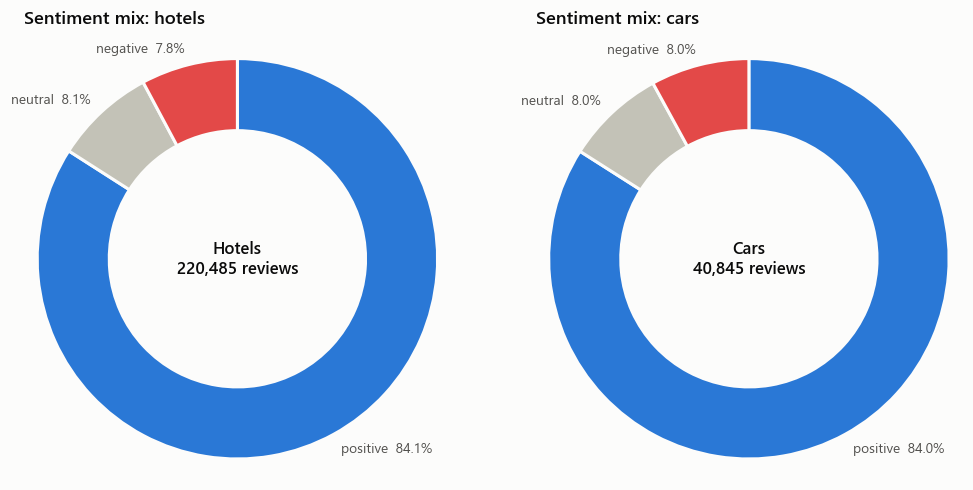

sent_class  neg  neu   pos
domain                    
car         8.0  8.0  84.0
hotel       7.8  8.1  84.1


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (dom, sub) in zip(axs, [("Hotels", H), ("Cars", C)]):
    sc = sub["sent_class"].value_counts().reindex(["pos", "neu", "neg"])
    P.doughnut(ax, sc.rename({"pos": "positive", "neu": "neutral", "neg": "negative"}),
               f"Sentiment mix: {dom.lower()}", [P.SENT[k] for k in sc.index], f"{dom}\n{len(sub):,} reviews")
P.save(fig, "p02_doughnut_sentiment")
plt.show()
print(pd.crosstab(df["domain"], df["sent_class"], normalize="index").mul(100).round(1))

**Inferences (doughnut chart)**
* Both sources are overwhelmingly positive: **~84 % positive** reviews, with only ~8 %
  negative and ~8 % neutral. This is the familiar positivity bias of online reviews.
* Car and hotel reviewers have an almost identical sentiment mix, even though the products and
  websites differ.
* The negative class is a small minority. Any rule or pattern that predicts negative reviews
  will have low support, which shapes the ARM parameter choices in notebook 03.

### Plot 3 · Histogram: review length

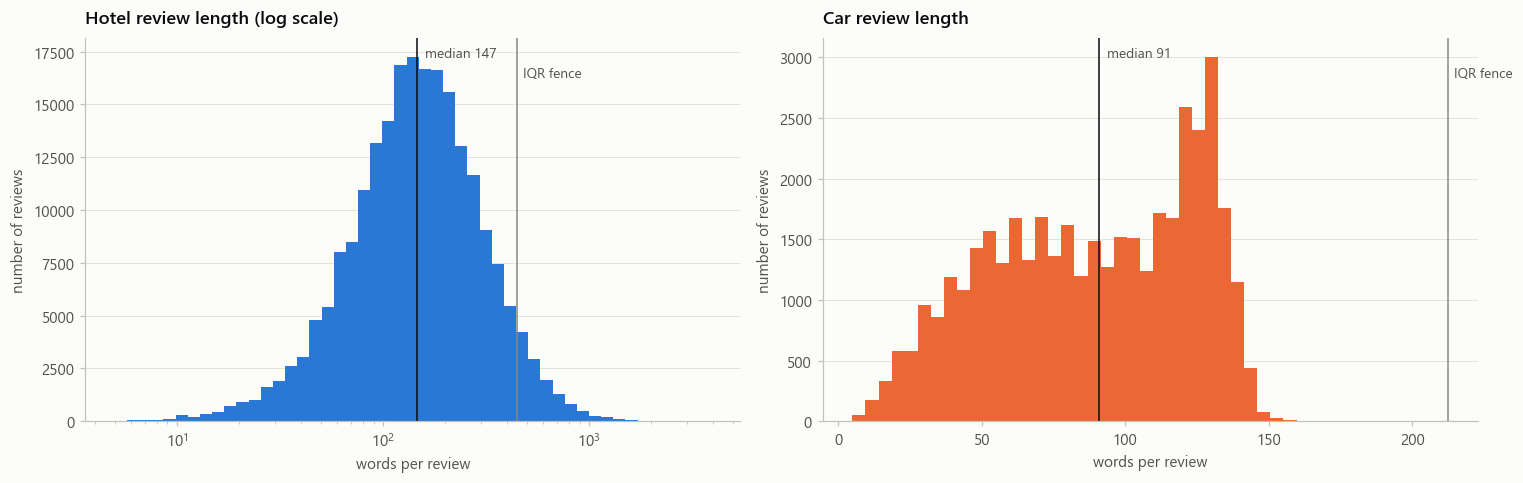

           count   mean    std  min   25%    50%    75%    95%    99%     max
domain                                                                       
car      40845.0   88.6   35.0  5.0  60.0   91.0  121.0  136.0  143.0   187.0
hotel   220485.0  185.2  148.7  5.0  91.0  147.0  233.0  460.0  740.0  3885.0
skewness: {'car': -0.27, 'hotel': 2.93}  IQR fences: {'car': 212, 'hotel': 446}


In [10]:
fence = {d: g["word_count"].quantile(0.75) + 1.5 * (g["word_count"].quantile(0.75) - g["word_count"].quantile(0.25))
         for d, g in df.groupby("domain")}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
P.histogram(axs[0], H["word_count"], "Hotel review length (log scale)", P.DOMAIN["hotel"], "words per review",
            bins=50, logx=True)
P.histogram(axs[1], C["word_count"], "Car review length", P.DOMAIN["car"], "words per review", bins=40)
for ax, d in zip(axs, ["hotel", "car"]):
    ax.axvline(fence[d], color=P.MUTED, lw=1)
    ax.annotate("IQR fence", xy=(fence[d], 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0),
                textcoords="offset points", color=P.INK2, fontsize=9)
fig.tight_layout()
P.save(fig, "p03_histogram_length")
plt.show()
print(df.groupby("domain")["word_count"].describe(percentiles=[.25, .5, .75, .95, .99]).round(1))
print("skewness:", df.groupby("domain")["word_count"].skew().round(2).to_dict(), " IQR fences:", {k: round(v) for k, v in fence.items()})

**Inferences (histograms)**
* **Hotel reviews are strongly right-skewed** (skewness ≈ 2.9). Median ≈ 147 words, mean ≈ 185,
  and a long tail up to several thousand words. On the log axis the distribution looks roughly
  normal, i.e. the lengths are approximately log-normal. About 5 % lie beyond the IQR fence
  (≈ 446 words).
* **Car reviews behave quite differently**: median ≈ 91 words, nothing above ≈ 190 words, and
  a slight *left* skew (−0.3). The hard ceiling and the pile-up just below it suggest the
  Edmunds form limited review length.
* The two sources therefore need separate (per-domain) normalisation and binning. That is why
  `wc_minmax`, `wc_z` and `len_class` are computed per domain.

### Plot 4 · Dot plot: models reviewed per car make

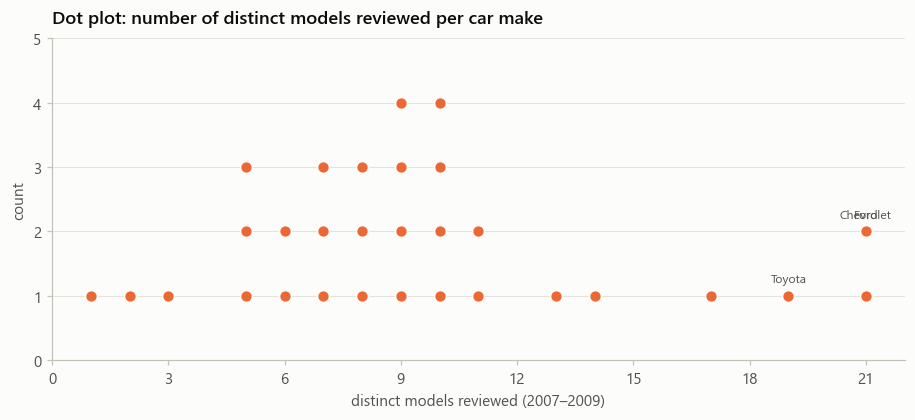

make
Smart             1
Mini              2
Scion             3
Acura             5
Suzuki            5
Buick             5
Jeep              6
Subaru            6
Infiniti          7
Chrysler          7
Saturn            7
Pontiac           8
Mitsubishi        8
Cadillac          8
Honda             9
GMC               9
Volvo             9
Kia               9
Mazda            10
Mercedes-Benz    10
Lexus            10
BMW              10
Audi             11
Hyundai          11
Volkswagen       13
Dodge            14
Nissan           17
Toyota           19
Ford             21
Chevrolet        21
median: 9.0  mean: 9.37


In [11]:
models_per_make = C.groupby("make")["model"].nunique().sort_values()
fig, ax = plt.subplots(figsize=(10, 3.8))
P.dot_plot(ax, models_per_make.values, "Dot plot: number of distinct models reviewed per car make",
           P.DOMAIN["car"], "distinct models reviewed (2007–2009)")
top = models_per_make.tail(3)
for m, v in top.items():
    ax.annotate(m, xy=(v, (models_per_make == v).sum()), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8, color=P.INK2)
P.save(fig, "p04_dotplot_models_per_make")
plt.show()
print(models_per_make.to_string())
print("median:", models_per_make.median(), " mean:", round(models_per_make.mean(), 2))

**Inferences (dot plot)**
* Most makes have between 5 and 14 models reviewed (median 9). The distribution is moderately
  right-skewed, with three high outliers: **Chevrolet and Ford (21 models each) and Toyota (19)**.
* The niche brands sit at the low end: Smart (1), Mini (2), Scion (3).
* Each dot is one make, so the individual values stay visible. With only 30 values, a dot plot
  shows more than a histogram would for small data.

### Plot 5 · Stem-and-leaf: reviews per car model-year file for one make (Honda)

In [12]:
honda = C[C["make"] == "Honda"].groupby(["model_year", "model"]).size()
stem = P.stem_and_leaf(honda.values)
print(stem)
fig = P.text_figure(stem, f"Stem-and-leaf: reviews per Honda model and model year ({len(honda)} values)")
P.save(fig, "p05_stem_leaf_honda")
plt.show()
print(honda.sort_values(ascending=False).to_string())

0 | 1 1 2 6 6 6 6 8
1 | 0 1 1 3 5 6 7 9
2 | 1 2 2 7 9
3 | 5
4 | 3 3

Key: 1 | 2 = 120   (leaf unit 10; values truncated)


<Figure size 825x276.1 with 0 Axes>

model_year  model    
2008.0      civic        436
2007.0      civic        430
            fit          358
            cr-v         299
            accord       276
2008.0      cr-v         228
2009.0      accord       224
2007.0      odyssey      211
2009.0      fit          194
            civic        171
2008.0      fit          161
2009.0      pilot        155
2007.0      pilot        135
2008.0      odyssey      118
2009.0      cr-v         113
2007.0      ridgeline    107
2008.0      ridgeline     85
2007.0      element       67
2008.0      pilot         66
            element       62
2009.0      odyssey       60
2007.0      s2000         29
2009.0      ridgeline     18
2008.0      s2000         12


**Inferences (stem-and-leaf)**
* The 24 Honda model-year files range from about 10 to 440 reviews. Two thirds sit on the
  first two stems (fewer than 200 reviews).
* The display keeps the actual values, so the **outliers** are easy to name: the Civic
  (2007: 430, 2008: 436) collects about twice the reviews of any other Honda. The S2000 sports
  car is at the bottom (12–29).
* The shape is right-skewed: a few blockbuster models and many modestly reviewed ones. That is
  the same long-tail pattern the Pareto chart shows for hotels.

### Plot 6 · Scatter plot: popularity vs mean sentiment

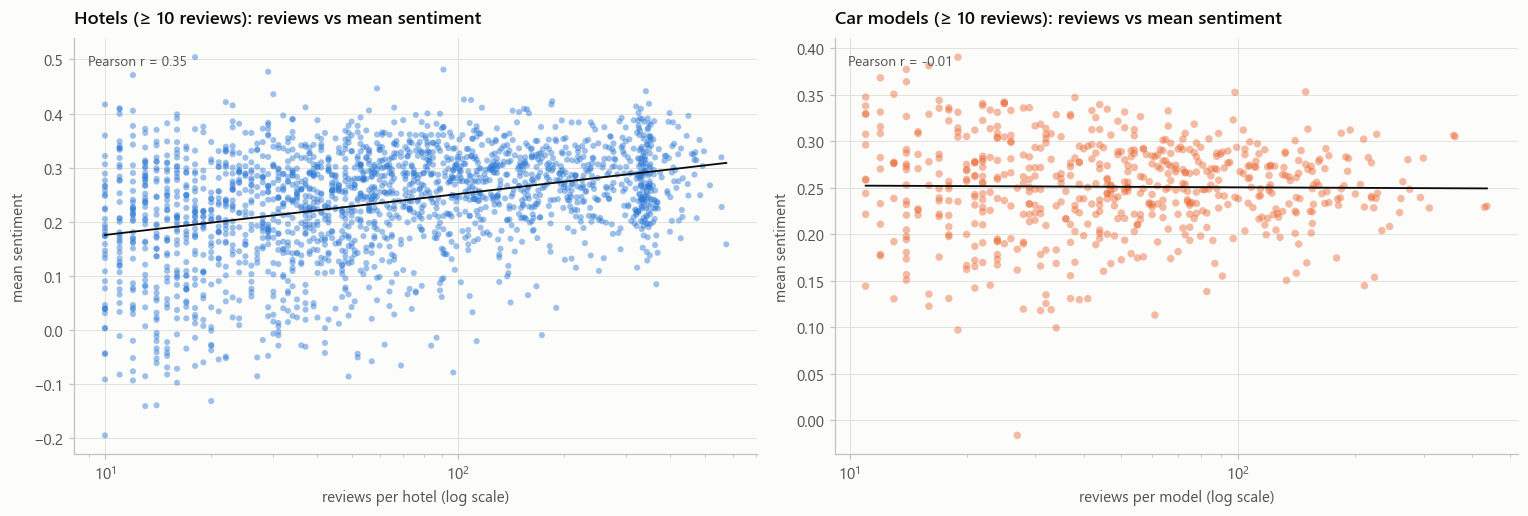

hotels: n = 2069, r = 0.348;  car models: n = 596, r = -0.013
lowest-rated hotels:
                               n      s
city_name entity                      
London    Abbey Lodge Hotel  10 -0.195
          Warwick Hotel      13 -0.141
          Berkeley Court     14 -0.139
highest-rated hotels:
                                        n      s
city_name entity                               
New Delhi Amarya Garden               18  0.504
          Hotel Raunak International  91  0.481
London    Church Street Hotel         29  0.477


In [13]:
ph = H.groupby(["city_name", "entity"]).agg(n=("sentiment", "size"), s=("sentiment", "mean"))
ph = ph[ph["n"] >= 10]
pc = C.groupby(["model_year", "entity"]).agg(n=("sentiment", "size"), s=("sentiment", "mean"))
pc = pc[pc["n"] >= 10]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
r_h = P.scatter(axs[0], ph["n"], ph["s"], "Hotels (≥ 10 reviews): reviews vs mean sentiment",
                "reviews per hotel (log scale)", "mean sentiment", P.DOMAIN["hotel"], logx=True)
r_c = P.scatter(axs[1], pc["n"], pc["s"], "Car models (≥ 10 reviews): reviews vs mean sentiment",
                "reviews per model (log scale)", "mean sentiment", P.DOMAIN["car"], logx=True, s=24)
fig.tight_layout()
P.save(fig, "p06_scatter_popularity_sentiment")
plt.show()
print(f"hotels: n = {len(ph)}, r = {r_h:.3f};  car models: n = {len(pc)}, r = {r_c:.3f}")
print("lowest-rated hotels:\n", ph.nsmallest(3, "s").round(3).to_string())
print("highest-rated hotels:\n", ph.nlargest(3, "s").round(3).to_string())

**Inferences (scatter plots)**
* For hotels there is a **moderate positive relationship** (r ≈ 0.35) between how many reviews
  a hotel has (log scale) and how positive they are on average. Popular hotels tend to be
  liked. Correlation is not causation: good hotels may attract more guests, or many reviews may
  average out extreme opinions.
* The spread **narrows as the review count grows**: mean sentiment is noisy for hotels with
  10–30 reviews and stable for hotels with hundreds. This is another reason to drop
  small-sample entities.
* For car models there is **no relationship** (r ≈ 0). A model's popularity on Edmunds says
  nothing about how positive its reviews are.

### Plot 7 · Box plots: sentiment by city, length by car model year

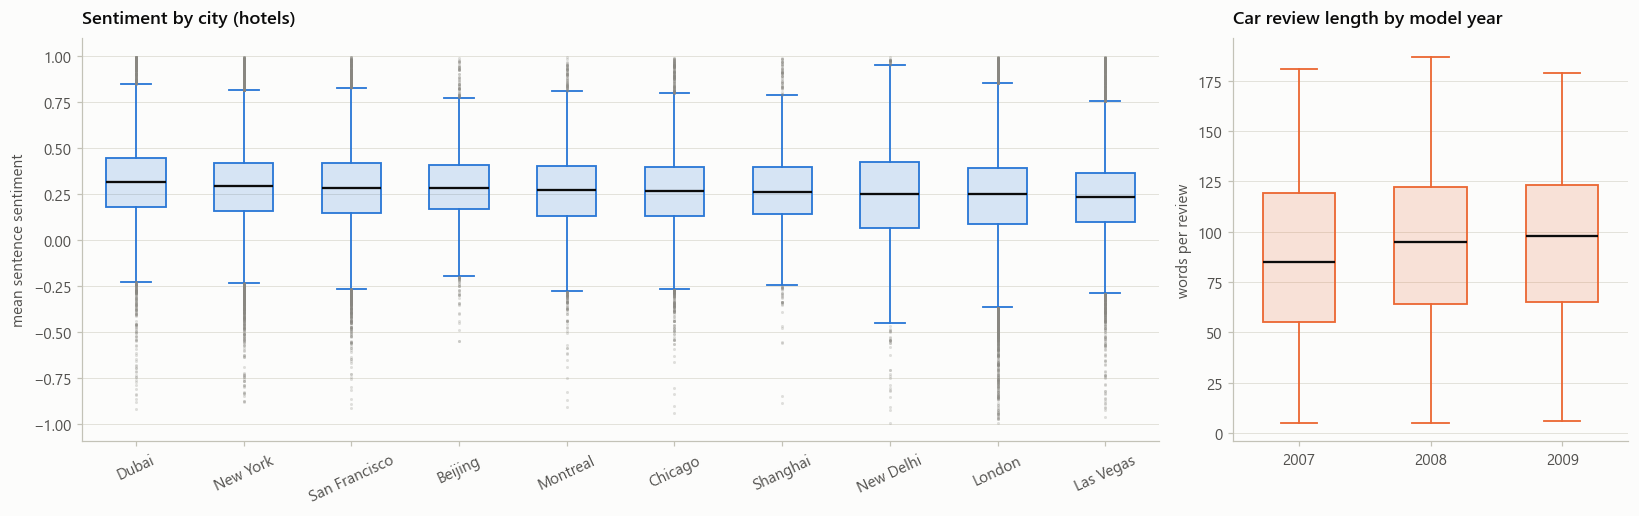

                 min    25%    50%    75%    max    IQR
city_name                                              
Dubai         -0.916  0.179  0.314  0.448  0.998  0.269
New York      -0.881  0.160  0.293  0.422  0.998  0.262
San Francisco -0.911  0.147  0.286  0.420  0.998  0.274
Beijing       -0.550  0.168  0.283  0.411  0.992  0.243
Montreal      -0.907  0.130  0.275  0.402  0.998  0.272
Chicago       -0.941  0.133  0.268  0.399  0.992  0.267
Shanghai      -0.884  0.141  0.265  0.401  0.992  0.260
New Delhi     -0.993  0.069  0.253  0.423  0.996  0.354
London        -0.992  0.091  0.249  0.396  0.996  0.305
Las Vegas     -0.959  0.102  0.234  0.364  0.999  0.262
             25%   50%    75%
model_year                   
2007.0      55.0  85.0  119.0
2008.0      64.0  95.0  122.0
2009.0      65.0  98.0  123.0


In [14]:
order = H.groupby("city_name")["sentiment"].median().sort_values(ascending=False).index
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [3, 1.1]})
P.boxplot(axs[0], {c: H.loc[H["city_name"] == c, "sentiment"].values for c in order},
          "Sentiment by city (hotels)", P.DOMAIN["hotel"], "mean sentence sentiment")
axs[0].tick_params(axis="x", rotation=25)
P.boxplot(axs[1], {str(y): C.loc[C["model_year"] == y, "word_count"].values for y in [2007, 2008, 2009]},
          "Car review length by model year", P.DOMAIN["car"], "words per review")
fig.tight_layout()
P.save(fig, "p07_boxplot_sentiment_city")
plt.show()
five = H.groupby("city_name")["sentiment"].describe()[["min", "25%", "50%", "75%", "max"]]
five["IQR"] = five["75%"] - five["25%"]
print(five.loc[order].round(3).to_string())
print(C.groupby("model_year")["word_count"].describe()[["25%", "50%", "75%"]].to_string())

**Inferences (box plots), using the box-plot comparison rules**
* Median sentiment ranges from ≈ 0.31 (Dubai) down to ≈ 0.23 (Las Vegas). Every box overlaps
  every other and each median lies inside the others' boxes, so by the comparison rule **no city
  can be called clearly different**. The differences are real but small.
* **New Delhi has the tallest box** (IQR ≈ 0.35 vs ≈ 0.26 elsewhere): its reviews are the most
  polarised. London and Las Vegas sit lowest.
* Every city has a long lower tail of outliers down to about −0.99: a small number of very
  negative reviews, against a body that is mildly positive.
* Car reviews got slightly longer with newer model years (median 85 → 95 → 98 words) while
  keeping the same spread.

### Plot 8 · Pareto chart
Shown in the data-selection section: (a) aspect mentions, which drive the vocabulary
selection; (b) reviews per hotel, which drives the row filter.

### Plot 9 · Radar chart: aspect emphasis of the three largest cities and makes
Each axis is an **index** = (share of the group's reviews that mention the aspect) ÷ (share
across the whole domain). 1.0 is the domain average, drawn as the black ring. Indexing puts axes
with very different base rates (room vs view) on one comparable scale.

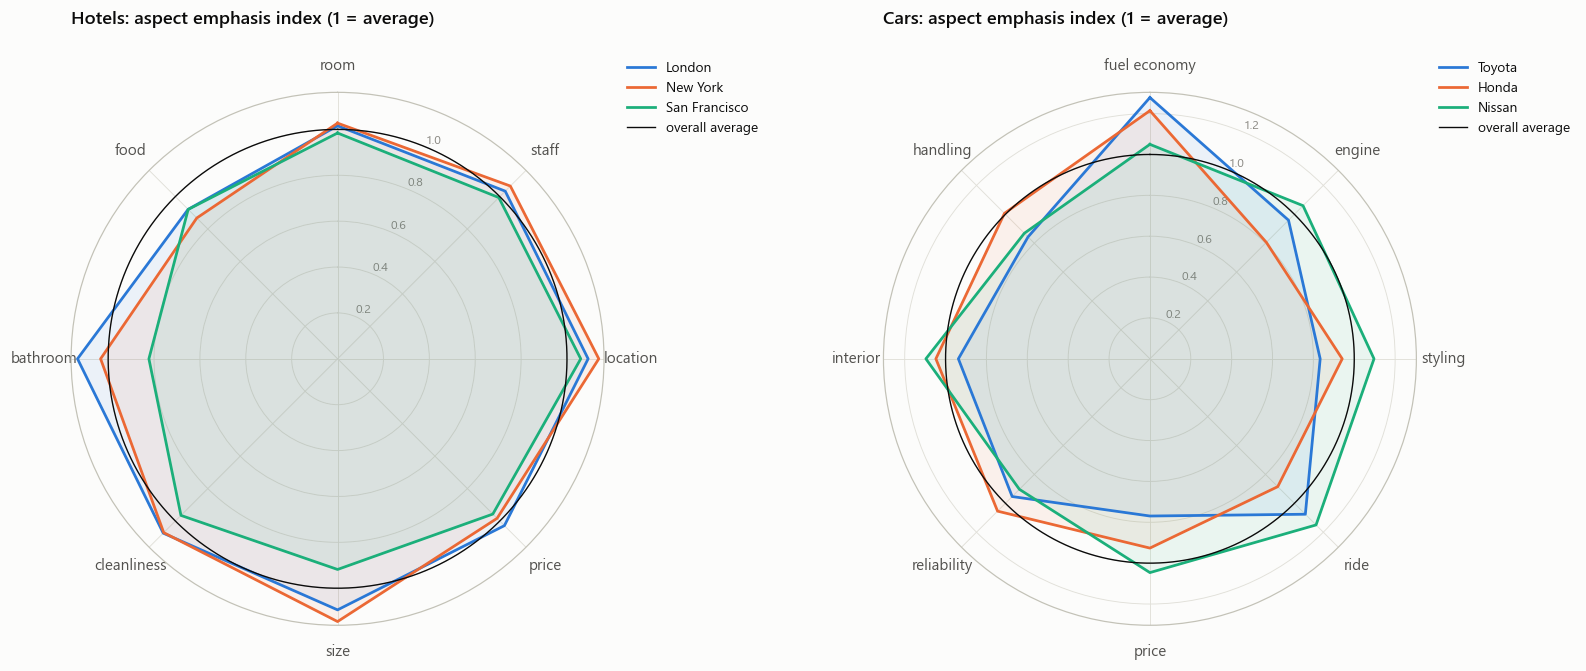

aspects        room  staff  location  price  size  cleanliness  bathroom  food
city_name                                                                     
London         1.02   1.03      1.09   1.03  1.09         1.07      1.13  0.92
New York       1.03   1.07      1.14   0.98  1.15         1.07      1.03  0.87
San Francisco  0.98   0.99      1.06   0.96  0.92         0.97      0.82  0.92
aspects  fuel economy  engine  styling  ride  price  reliability  interior  handling
make                                                                                
Toyota           1.28    0.96     0.83  1.08   0.77         0.95      0.94      0.84
Honda            1.21    0.81     0.94  0.88   0.93         1.05      1.05      1.01
Nissan           1.05    1.06     1.10  1.15   1.05         0.90      1.10      0.87


In [15]:
def emphasis(sub, by, groups, aspects):
    ex = sub[[by, "aspects"]].explode("aspects").reset_index(drop=True)   # one row per mention
    ct = pd.crosstab(ex[by], ex["aspects"])[aspects]
    rate = ct.div(sub[by].value_counts(), axis=0)
    overall = ct.sum() / len(sub)
    return (rate.loc[groups] / overall).rename(columns=lambda a: a.replace("_", " "))


top_cities = city_counts.index[:3]
top_makes = C["make"].value_counts().index[:3]
rad_h = emphasis(H, "city_name", top_cities, list(asp_h.index[:8]))
rad_c = emphasis(C, "make", top_makes, list(asp_c.index[:8]))
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2), subplot_kw={"projection": "polar"})
P.radar(axs[0], rad_h, "Hotels: aspect emphasis index (1 = average)")
P.radar(axs[1], rad_c, "Cars: aspect emphasis index (1 = average)")
fig.tight_layout()
P.save(fig, "p09_radar_aspect_emphasis")
plt.show()
print(rad_h.round(2).to_string())
print(rad_c.round(2).to_string())

**Inferences (radar charts)**
* **London** reviewers over-mention *bathroom* (index ≈ 1.13), *location* and *room size*
  (≈ 1.09). **New York** reviewers stress *size* (≈ 1.15) and *location* (≈ 1.14), consistent
  with small rooms in dense city centres. **San Francisco** reviews mention bathrooms (≈ 0.82)
  and size (≈ 0.92) *less* than average.
* Among cars, **Toyota (≈ 1.28) and Honda (≈ 1.21) reviews are dominated by fuel economy**,
  while **Nissan** reviews lean towards *ride* (≈ 1.15), *styling* and *interior* (≈ 1.10).
  Toyota reviewers mention *price* least (≈ 0.77).
* Indexing against the domain average puts all axes on one scale. Without it, the radar would
  only repeat the Pareto ranking (room ≫ everything else).

### Plot 10 · Stacked area chart: review volume over time

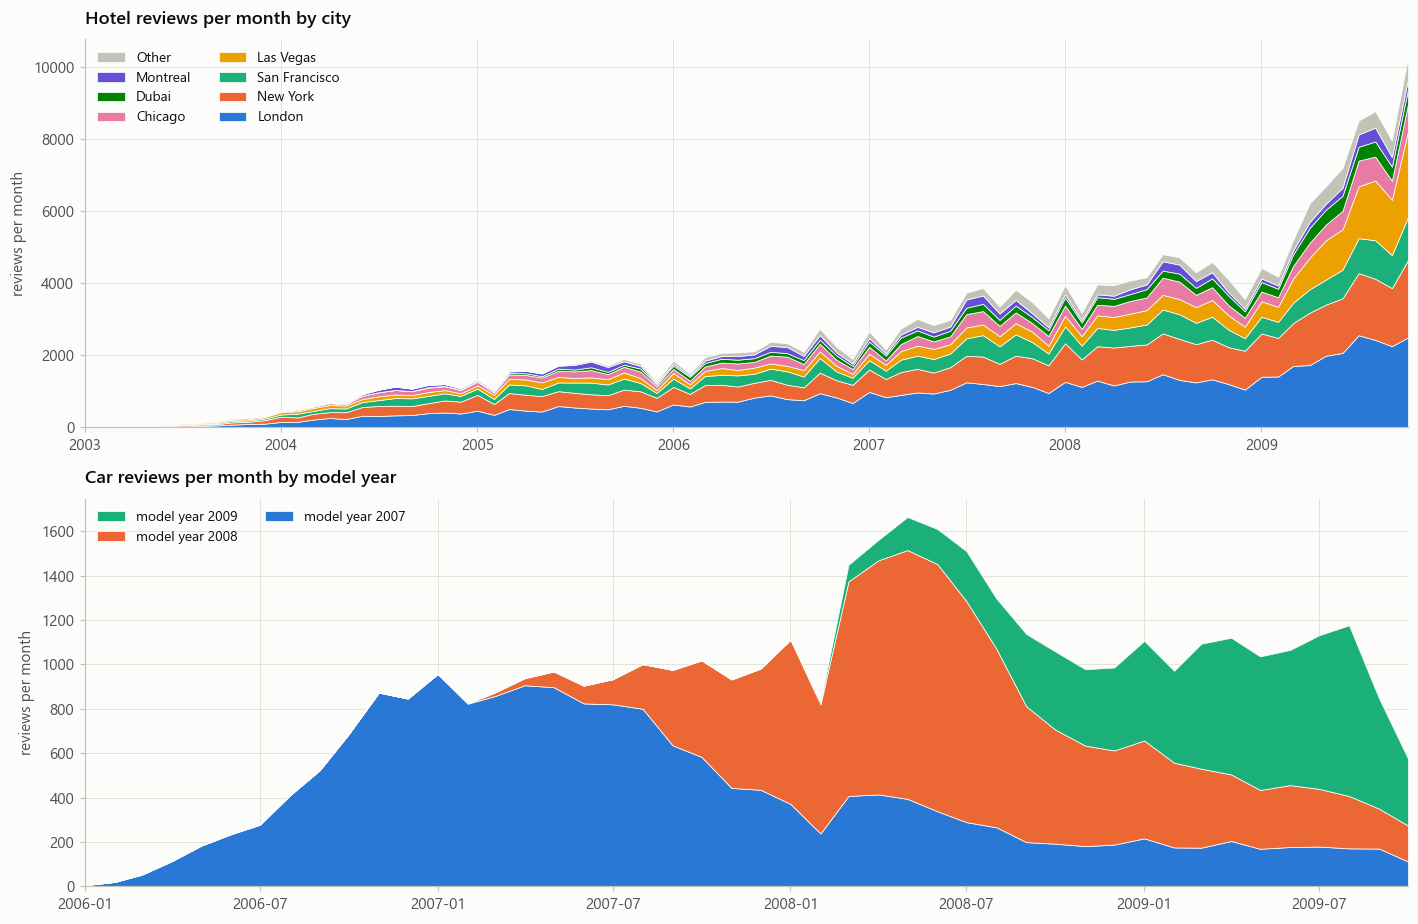

hotel reviews per year: {np.int64(2001): 1, np.int64(2002): 70, np.int64(2003): 1447, np.int64(2004): 10485, np.int64(2005): 18926, np.int64(2006): 25119, np.int64(2007): 37549, np.int64(2008): 49229, np.int64(2009): 76106}  growth 2005->2008: 2.6
busiest hotel months (all years): {np.int64(10): 24695, np.int64(8): 22774, np.int64(7): 22302, np.int64(9): 20618}
car reviews by (review year x model year):
 model_year  2007.0  2008.0  2009.0
year                              
2006          4228       0       0
2007          8980    2324       0
2008          3477    9383    2332
2009          1747    2861    5513


In [16]:
mh = H.dropna(subset=["date"]).assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp())
ts_h = mh.groupby(["month", "city_name"]).size().unstack(fill_value=0).loc["2003-01-01":"2009-10-31"]
mc = C.dropna(subset=["date"]).assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp())
ts_c = mc.groupby(["month", "model_year"]).size().unstack(fill_value=0)
ts_c.columns = [f"model year {int(c)}" for c in ts_c.columns]
fig, axs = plt.subplots(2, 1, figsize=(13, 8.5))
P.stacked_area(axs[0], ts_h, "Hotel reviews per month by city", palette=CITY_COLORS)
P.stacked_area(axs[1], ts_c, "Car reviews per month by model year")
fig.tight_layout()
P.save(fig, "p10_area_reviews_over_time")
plt.show()
yearly = H.groupby("year").size()
print("hotel reviews per year:", yearly.to_dict(), " growth 2005->2008:", round(yearly[2008] / yearly[2005], 2))
print("busiest hotel months (all years):", H.groupby("month").size().sort_values(ascending=False).head(4).to_dict())
print("car reviews by (review year x model year):\n", pd.crosstab(C["year"], C["model_year"]))

**Inferences (stacked area charts)**
* Hotel review volume **grows steadily from 2003 to 2009**: 2.6× between 2005 and 2008, and
  2009 alone has ~76k reviews. The data captures the rise of TripAdvisor more than any change in
  travel.
* There is a clear **seasonal cycle**: July–October are the busiest months (summer travel),
  with a dip each winter. London and New York form the base of the stack throughout; Las Vegas
  grows strongly in 2009.
* Car reviews show a **product life-cycle**. Each model year's reviews start about a year
  before the model year (MY2007 from early 2006), peak around launch, then decay as the next
  model year takes over.

## 4 · Supporting plots
### Plot 11 · Correlation heatmap: shown in section 1b (redundancy check)
### Plot 12 · Bar charts: reviews per car make; what cleaning removed or repaired

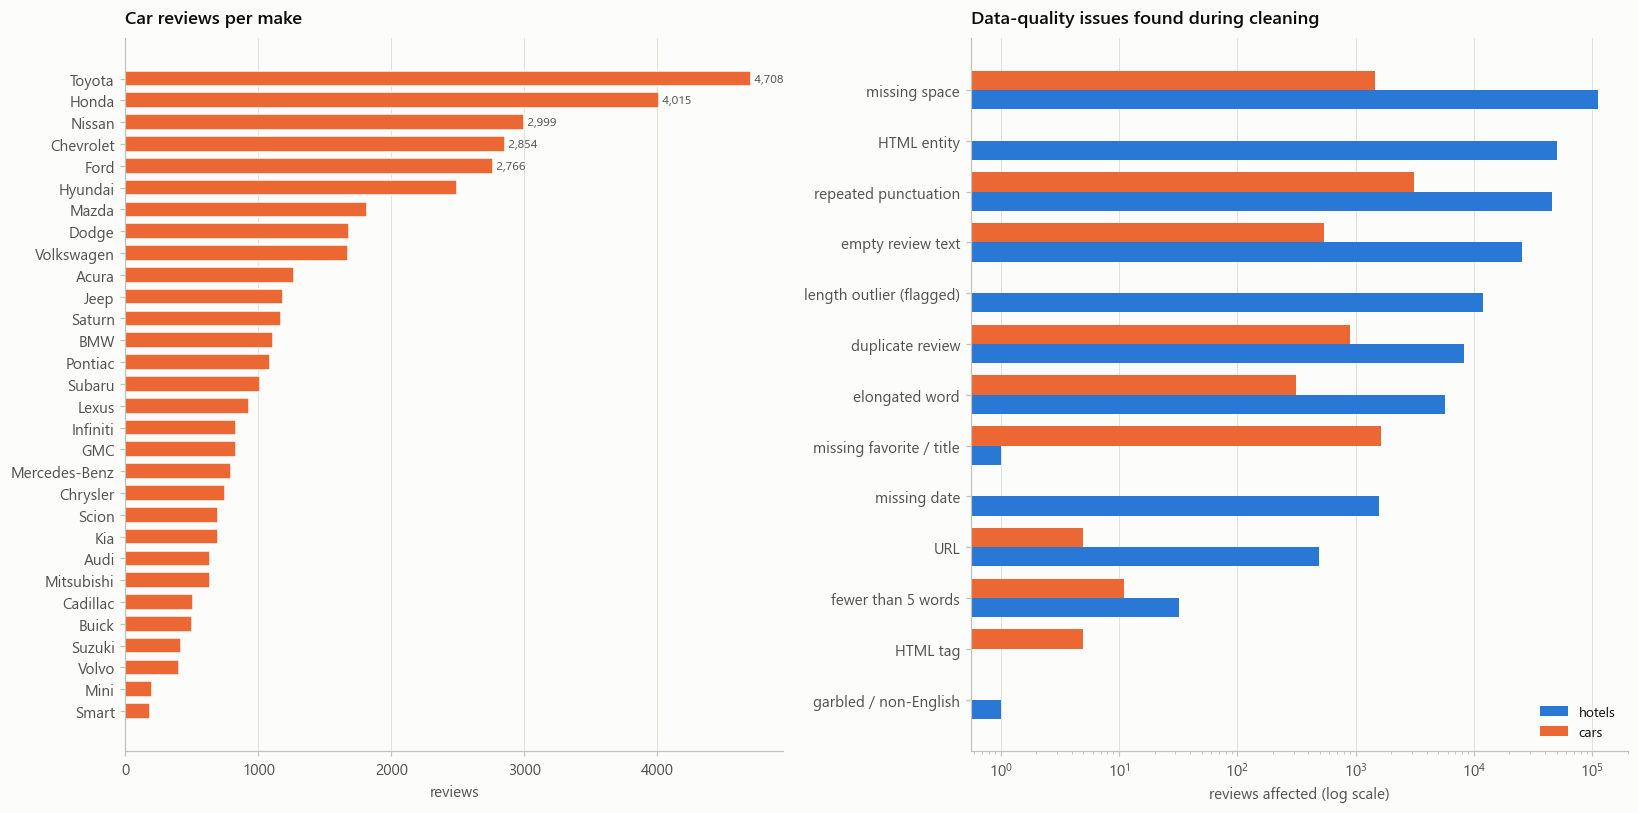

domain                     car   hotel
issue                                 
garbled / non-English        0       1
HTML tag                     5       0
fewer than 5 words          11      32
URL                          5     487
missing date                 0    1587
missing favorite / title  1639       1
elongated word             314    5749
duplicate review           892    8266
length outlier (flagged)     0   12040
empty review text          540   25789
repeated punctuation      3109   45672
HTML entity                  0   50213
missing space             1451  112400


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7.5))
P.hbar(axs[0], C["make"].value_counts(), "Car reviews per make", P.DOMAIN["car"], "reviews")
nc = (pd.read_csv(TABLES / "noise_counts.csv")
      .pivot_table(index="issue", columns="domain", values="count", aggfunc="sum", fill_value=0))
nc = nc[nc.sum(axis=1) > 0]
nc = nc.loc[nc.sum(axis=1).sort_values().index]
y = np.arange(len(nc))
axs[1].barh(y - 0.19, nc.get("hotel", 0), 0.38, color=P.DOMAIN["hotel"], label="hotels")
axs[1].barh(y + 0.19, nc.get("car", 0), 0.38, color=P.DOMAIN["car"], label="cars")
axs[1].set_yticks(y)
axs[1].set_yticklabels(nc.index)
axs[1].set_xscale("log")
axs[1].set_xlabel("reviews affected (log scale)")
axs[1].set_title("Data-quality issues found during cleaning")
axs[1].legend(loc="lower right")
axs[1].grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "s12_bar_makes_and_cleaning")
plt.show()
print(nc.to_string())

**Inferences (bar charts)**
* Five makes (Toyota, Honda, Nissan, Chevrolet, Ford) supply about 42 % of all car reviews.
  Toyota alone has ~4.7k.
* The most common quality problems were **cosmetic but massive**: about half of all hotel
  reviews had missing spaces where lines were joined, and ~50k had HTML entities. Both were
  repaired, not dropped.
* The rows actually **removed** came mainly from empty texts (~26k) and duplicates (~9k).
  Language and length filters removed only a few dozen rows, so the cleaned data keeps
  ~88 % of the raw records.

### Plot 13 · Line chart: mean sentiment per month

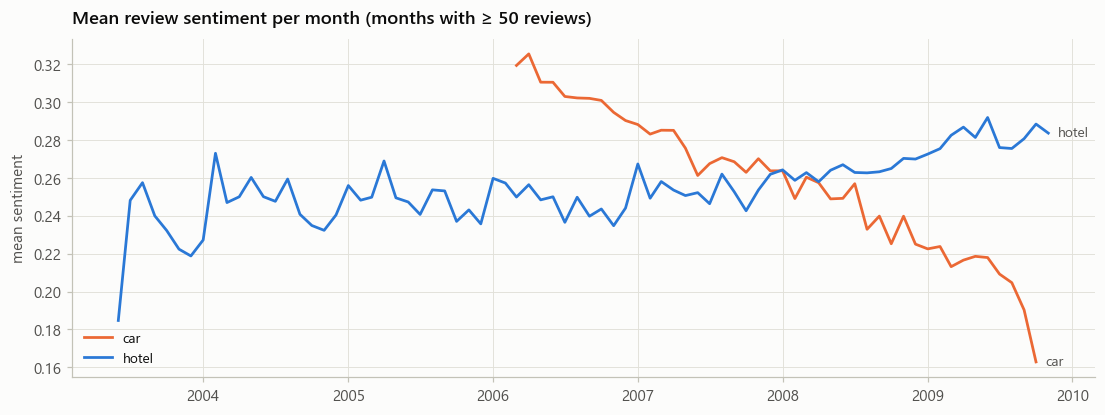

domain    car  hotel
year                
2001      NaN  0.422
2002      NaN  0.164
2003      NaN  0.227
2004      NaN  0.246
2005      NaN  0.248
2006    0.300  0.247
2007    0.273  0.254
2008    0.247  0.264
2009    0.210  0.282


In [18]:
sm = pd.concat([mh.assign(d="hotel"), mc.assign(d="car")]).groupby(["month", "d"])["sentiment"].agg(["mean", "size"])
sm = sm[sm["size"] >= 50]["mean"].unstack()
fig, ax = plt.subplots(figsize=(12, 4))
P.lines(ax, sm.loc["2003-01-01":], "Mean review sentiment per month (months with ≥ 50 reviews)", "mean sentiment",
        colors=P.DOMAIN)
P.save(fig, "s13_line_sentiment_trend")
plt.show()
print(df.groupby(["domain", "year"])["sentiment"].mean().unstack(0).round(3))

**Inferences (line chart)**
* Hotel sentiment drifts slowly **upwards** (yearly mean ≈ 0.25 in 2004–06 → ≈ 0.28 in 2009).
* Car sentiment drifts **downwards** (≈ 0.30 in 2006 → ≈ 0.21 in 2009). A plausible reading:
  early reviews of a model come from enthusiastic first buyers, while later ones include
  long-term owners reporting problems (see the reliability and dealer rules in notebook 03).
* The two series move in opposite directions, so a review site's overall mood is not
  constant. Time is a relevant attribute when comparing entities.

### Plot 14 · 100 % stacked bar: sentiment class share by city and by make

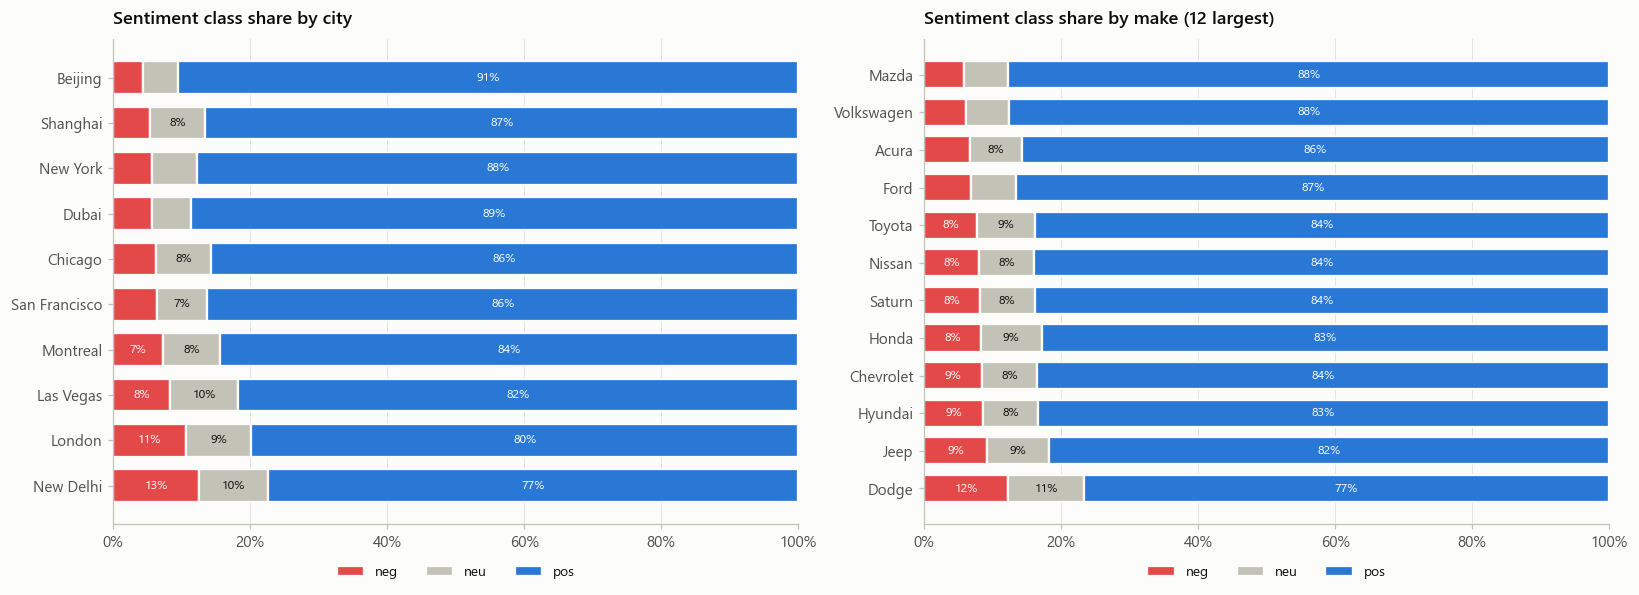

sent_class      neg   neu   pos
city_name                      
Beijing         4.4   5.1  90.6
Shanghai        5.4   8.0  86.6
New York        5.6   6.6  87.8
Dubai           5.7   5.6  88.7
Chicago         6.3   7.9  85.8
San Francisco   6.3   7.4  86.3
Montreal        7.2   8.4  84.4
Las Vegas       8.4   9.8  81.9
London         10.6   9.5  79.9
New Delhi      12.5  10.1  77.4
sent_class   neg   neu   pos
make                        
Mazda        5.8   6.5  87.7
Volkswagen   6.1   6.2  87.7
Acura        6.7   7.5  85.8
Ford         6.9   6.5  86.6
Toyota       7.7   8.5  83.8
Nissan       8.0   8.0  84.0
Saturn       8.1   8.0  83.9
Honda        8.3   8.8  82.9
Chevrolet    8.5   8.0  83.5
Hyundai      8.6   7.9  83.4
Jeep         9.2   9.0  81.8
Dodge       12.3  11.0  76.7


In [19]:
ct_city = pd.crosstab(H["city_name"], H["sent_class"])[["neg", "neu", "pos"]]
ct_city = ct_city.loc[(ct_city["neg"] / ct_city.sum(axis=1)).sort_values().index]
top_makes12 = C["make"].value_counts().index[:12]
ct_make = pd.crosstab(C["make"], C["sent_class"])[["neg", "neu", "pos"]].loc[top_makes12]
ct_make = ct_make.loc[(ct_make["neg"] / ct_make.sum(axis=1)).sort_values().index]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
sh_city = P.stacked_share(axs[0], ct_city, "Sentiment class share by city", P.SENT)
sh_make = P.stacked_share(axs[1], ct_make, "Sentiment class share by make (12 largest)", P.SENT)
fig.tight_layout()
P.save(fig, "s14_stacked_sentiment_share")
plt.show()
print(sh_city.round(1).to_string())
print(sh_make.round(1).to_string())

**Inferences (100 % stacked bars)**
* The negative share varies almost 3× across cities: **Beijing ≈ 4 %** (the most positive) vs
  **London ≈ 11 % and New Delhi ≈ 12.5 %**.
* Among the 12 largest makes, **Dodge has the highest negative share (≈ 12 %)**, while Mazda and
  Volkswagen have the lowest (≈ 6 %).
* Unlike the pie and doughnut, stacked bars make these part-of-whole differences easy to compare
  across many groups at once.

## 5 · Save the task-relevant dataset for the mining notebooks
Rows: all car reviews, plus hotel reviews of hotels with at least 10 reviews (1c).
Attributes: drop the redundant `char_count` (1b) and the ID-like / technical fields (1a), and
keep the transformed attributes (2a, 2b).

In [20]:
keep_hotels = per_hotel[per_hotel >= 10].index
mask = (df["domain"] == "car") | df.set_index(["city_name", "entity"]).index.isin(keep_hotels)
cols = ["domain", "city_name", "entity", "make", "model", "model_year", "date", "year", "quarter", "month",
        "text", "word_count", "wc_minmax", "wc_z", "len_class", "sentence_count", "avg_word_len",
        "exclaim_count", "upper_ratio", "n_aspects", "aspects", "sentiment", "sent_class"]
model_df = df.loc[mask, cols].reset_index(drop=True)
model_df.to_parquet(CLEAN / "reviews_model.parquet", index=False)
print(f"saved {len(model_df):,} reviews x {len(cols)} attributes:", model_df["domain"].value_counts().to_dict())

saved 259,143 reviews x 23 attributes: {'hotel': 218298, 'car': 40845}
